# TP 1 ► Module : TAI (Traitement et Analyse d'Images)
> Pr. Gaceb<br>
> S1-Master I2A Pro

L’objectif de ce TP est de vous faire découvrir quelques bibliothèques Python spécialisées en vision par ordinateur. Les travaux effectués vous permettront de vous initier à la représentation d’une image numérique en mémoire, d'apprendre à ouvrir, modifier (manipuler au niveau pixel), afficher et sauvegarder une image.. 

In [2]:
import matplotlib.pyplot as plt
import numpy as np
import cv2

# Exercice 2 : Manipulations d’une image et bibliothèques spécialisées
Pour manipuler une image, plusieurs packages python existent. Pour commencer, on utilise la bibliothèque **OpenCV-Python**. Cette dernière est un wrapper Python pour OpenCV (pour Open Computer Vision), une bibliothèque logicielle open source développée initialement par Intel pour faire la vision par ordinateur et l'apprentissage automatique. Elle fournit un ensemble complet d'outils pour diverses tâches de vision par ordinateur, tirant parti de la simplicité et de la lisibilité de Python tout en bénéficiant des performances de l'implémentation C++ sous-jacente. Dans OpenCV-Python, les images sont fondamentalement représentées sous forme de tableaux NumPy, où chaque élément du tableau correspond à un pixel. Il est essentiel de comprendre comment accéder à chaque pixel et le manipuler pour effectuer diverses tâches de traitement d'images.

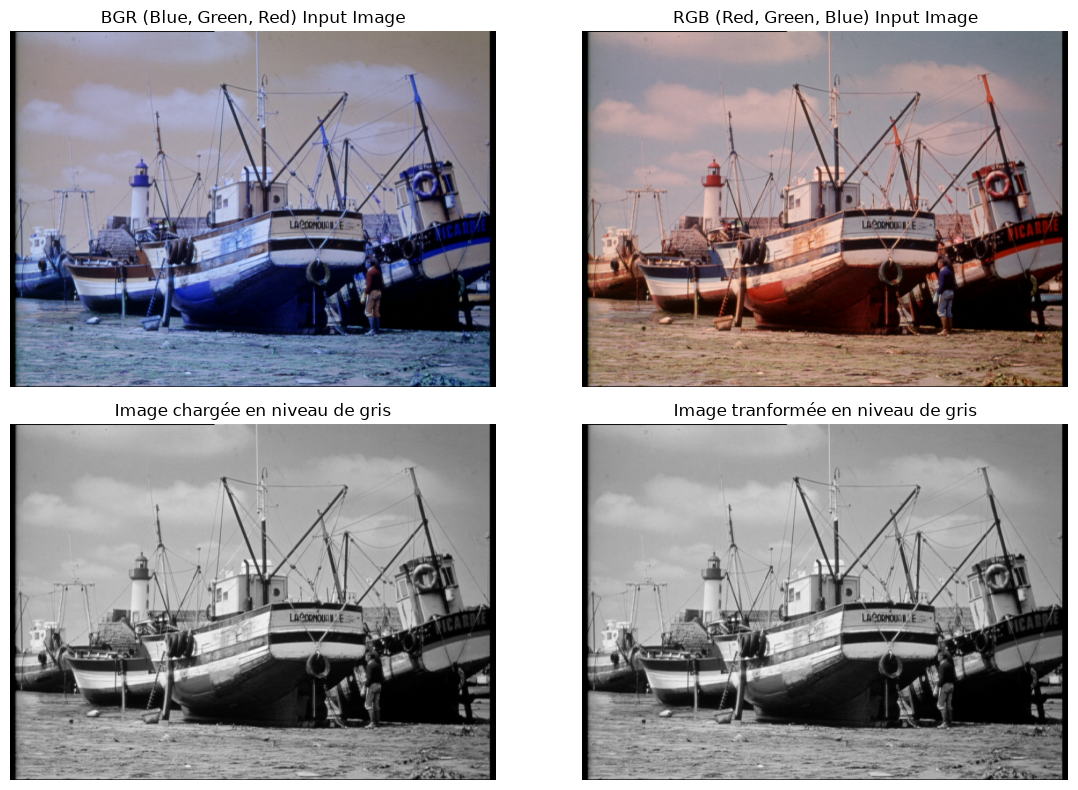

Les valeurs RGB de Pixel à (100, 150) sont : [170 166 197]
Height: 576 pixels
Width: 787 pixels
Channels: 3


In [121]:

# Lecture d'une image
bgr_img = cv2.imread('Images/BoatsColor.bmp')
assert bgr_img is not None, "Image not found! Check your path/data your dumbass!"

# Transformer une image BGR en image RGB
rgb_img =cv2.cvtColor(bgr_img, cv2.COLOR_BGR2RGB)

# Charger une image couleur avec sa conversion en niveaux de gris
gray_img = cv2.imread('Images/BoatsColor.bmp', cv2.IMREAD_GRAYSCALE)

# Transformer une image couleurs en une image en niveaux de gris
gray_img_converted = cv2.cvtColor(bgr_img, cv2.COLOR_BGR2GRAY)

# Affichage des images
fig, axes = plt.subplots(2, 2, figsize=(12, 8))

# pyplot expectes images to be RGB!
axes[0][0].imshow(bgr_img)
axes[0][0].set_title('BGR (Blue, Green, Red) Input Image')
axes[0][0].axis("off")

axes[0][1].imshow(rgb_img)
axes[0][1].set_title('RGB (Red, Green, Blue) Input Image')
axes[0][1].axis("off")

axes[1][0].imshow(gray_img, cmap="grey")
axes[1][0].set_title('Image chargée en niveau de gris')
axes[1][0].axis("off")

axes[1][1].imshow(gray_img_converted, cmap="grey")
axes[1][1].set_title('Image tranformée en niveau de gris')
axes[1][1].axis("off")

plt.tight_layout()
plt.show()

# Lecture des couleurs d'un pixel à la position at (100, 150)
pixel = bgr_img[100, 150]
print(f"Les valeurs RGB de Pixel à (100, 150) sont : {pixel}")

"""
Pour une image couleur, 'shape' contient trois valeurs : (hauteur, largeur, canaux).
- hauteur : nombre de lignes de pixels dans l'image.
- largeur : nombre de colonnes de pixels dans l'image.
- canaux : nombre de canaux de couleur (par exemple, 3 pour RGB, 1 pour les niveaux de gris).

Pour une image en niveaux de gris, 'shape' contient deux valeurs : (hauteur, largeur)
"""
height, width, channels = bgr_img.shape
print(f"Height: {height} pixels")
print(f"Width: {width} pixels")
print(f"Channels: {channels}")

# Exercice 3 : Seuillage fixe d’une image
On souhaite coder la binarisation de l’image `compteur.jpg`. Tous les pixels de $NG > 80$ sont convertis en Blanc et les pixels de $NG\leq80$ sont convertis en noir. Pour cela, développer un code permettant d’obtenir l’image binaire dans imgb1 en utilisant les fonctions openCV et l’image binaire imgb2 en utilisant votre code personnel. Enregistrer imgb1 dans le dossier 'Images/imgb1.jpg'.

im.shape=(381, 361)


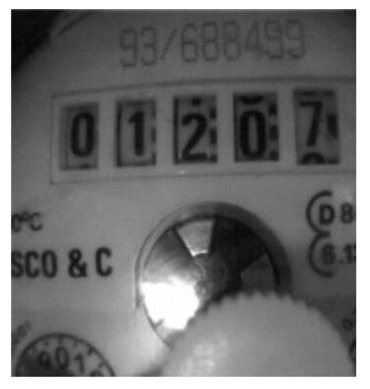

In [114]:

im = cv2.imread('Images/compteur.jpg', cv2.IMREAD_GRAYSCALE)
assert im is not None, "Image not found! Check your path/data your dumbass!"

print(f"{im.shape=}")

plt.imshow(im, cmap="grey")
plt.axis('off')
plt.show()

## 3.1. OpenCV

In [102]:
var, imgb1 = cv2.threshold(im, 80, 255, cv2.THRESH_BINARY)
imgb1

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255,   0, ..., 255, 255, 255],
       [255, 255,   0, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(381, 361), dtype=uint8)

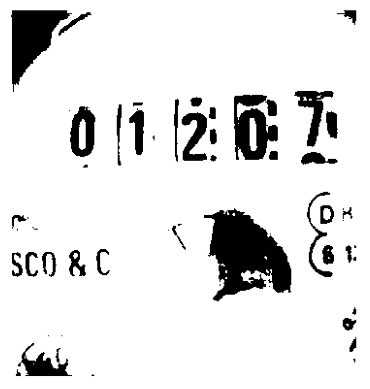

In [104]:
plt.imshow(imgb1, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

## 3.2. Custom Code

In [98]:
threshold = 80
foreground = im > threshold
background = im <= threshold
imgb2 = imgb1.copy()
imgb2[foreground] = 255
imgb2[background] = 0
imgb2

array([[255, 255, 255, ..., 255, 255, 255],
       [255, 255,   0, ..., 255, 255, 255],
       [255, 255,   0, ..., 255, 255, 255],
       ...,
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255],
       [255, 255, 255, ..., 255, 255, 255]], shape=(381, 361), dtype=uint8)

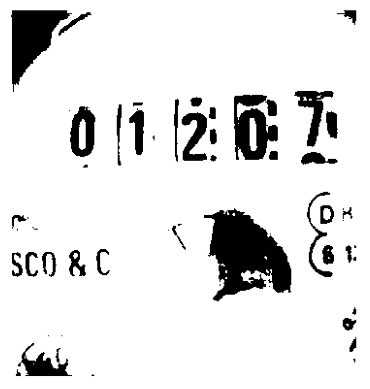

In [99]:
plt.imshow(imgb2, cmap="gray", vmin=0, vmax=255)
plt.axis("off")
plt.show()

# Exercice 4 : Manipulations simples sur des images numériques
On souhaite faire diverses manipulations sur l'image `im1`, lue à partir du fichier `Images/pepper.bmp`. Implémenter les instructions suivantes :
1. Lire l’image `im1`

In [122]:
im1 = cv2.imread('Images/pepper.bmp')
assert im1 is not None, "Image not found! Check your path/data your dumbass!"

2. Lire la taille de l’image `im1` dans `h` et `w`

Shape: 512 512 3


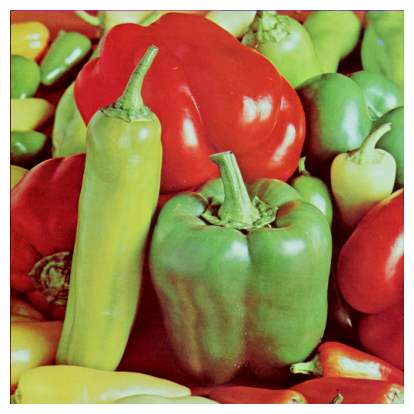

In [123]:

h, w, channels = im1.shape
print("Shape:", h, w, channels)

plt.figure(figsize=(h / dpi, w / dpi), dpi=dpi)
plt.imshow(cv2.cvtColor(im1, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

3. Redimensionner l'image im1 en divisant sa taille sur 2, stoker le résultat dans l’image 

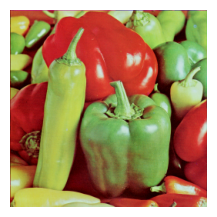

In [124]:

im2 = cv2.resize(im1, (w // 2, h // 2))
w2, h2 = im2.shape[:2]

dpi = 100
plt.figure(figsize=(w2 / dpi, h2 / dpi), dpi=dpi)
plt.imshow(cv2.cvtColor(im2, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

4. Cropper dans `im3` la région de l’image `im1` délimitée par le rectangle
$$ y_{start}=30  : y_{end}=150  $$
$$ x_{start}=200 : x_{end}=400 $$

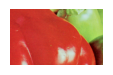

In [129]:
im3 = im1[30:150, 200:400]
h, w = im3.shape[:2]

dpi = 100
plt.figure(figsize=(h/dpi, w/dpi), dpi=dpi)
plt.imshow(cv2.cvtColor(im3, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

5. Copier `im1` dans `im4`, dessiner dans `im4` un rectangle bleu dans la zone

$$ y_{start}=30 : y_{end}=150 $$
$$ x_{start}=200: x_{end}=400 $$

puis saisir sur `im4` le texte suivant : "Mon rectangle" en couleur verte à la position $x=200, y=20$.

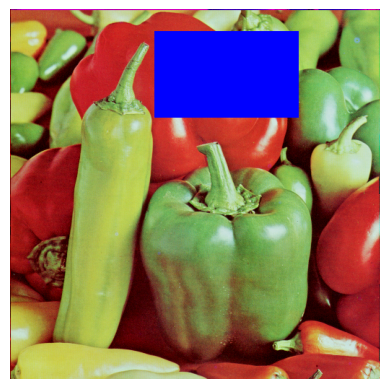

In [137]:
im4 = im1.copy()
im4[30:150, 200:400] = np.array([255, 0, 0])

plt.imshow(cv2.cvtColor(im4, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

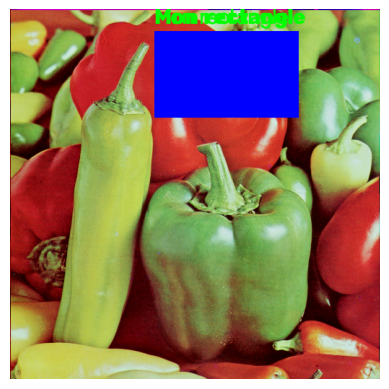

In [146]:
cv2.putText(im4, "Mon rectangle", (200, 20), cv2.FONT_HERSHEY_COMPLEX, 1.0, (0, 255, 0))
plt.imshow(cv2.cvtColor(im4, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

6. Appliquer à `im1` une rotation de $90^\circ$, charger le résultat dans `im5`.

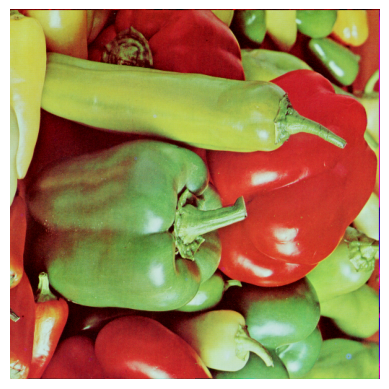

In [150]:
im5 = cv2.rotate(im1, cv2.ROTATE_90_CLOCKWISE)
plt.imshow(cv2.cvtColor(im5, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

7. Appliquer un flou Gaussien à l’image `im1`, stoker le résultat dans `im6`

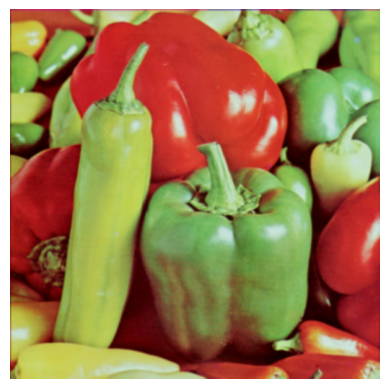

In [152]:
im6 = cv2.GaussianBlur(im1, (5, 5), 0)   # kernel size, sigmaX
plt.imshow(cv2.cvtColor(im6, cv2.COLOR_BGR2RGB))
plt.axis("off")
plt.show()

8. Afficher toutes les images créées

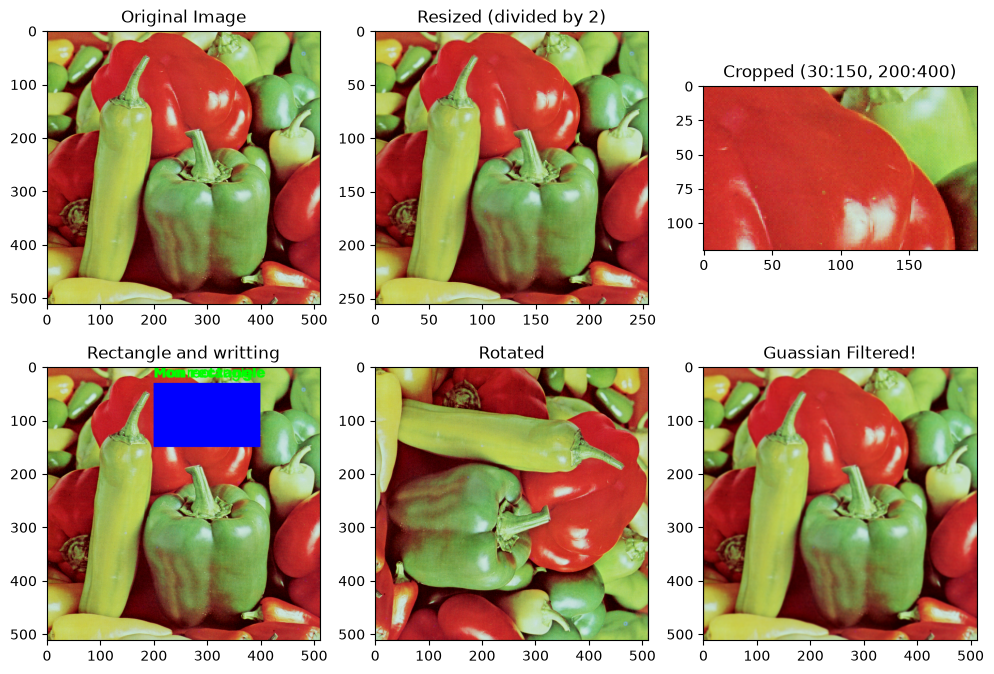

In [180]:
fig, axes = plt.subplots(2, 3, figsize=(12, 8))

axes[0][0].imshow(cv2.cvtColor(im1, cv2.COLOR_BGR2RGB))
axes[0][0].set_title("Original Image")
axes[0][1].imshow(cv2.cvtColor(im2, cv2.COLOR_BGR2RGB))
axes[0][1].set_title("Resized (divided by 2)")
axes[0][2].imshow(cv2.cvtColor(im3, cv2.COLOR_BGR2RGB))
axes[0][2].set_title("Cropped (30:150, 200:400)")

axes[1][0].imshow(cv2.cvtColor(im4, cv2.COLOR_BGR2RGB))
axes[1][0].set_title("Rectangle and writting")
axes[1][1].imshow(cv2.cvtColor(im5, cv2.COLOR_BGR2RGB))
axes[1][1].set_title("Rotated")
axes[1][2].imshow(cv2.cvtColor(im6, cv2.COLOR_BGR2RGB))
axes[1][2].set_title("Guassian Filtered!")

plt.show()

# Exercice 5 : Histogramme d’une image   

Un histogramme d’une image en niveaux de gris est une représentation graphique qui illustre la  répartition de l’intensité lumineuse d'une image, en spécifiant le nombre de pixels présents pour  chaque niveau de gris (de 0 à 255). Il facilite l'évaluation de la qualité de l’image (sur-exposition,  sous-exposition) et la modification de son contraste en étendant ou comprimant l'histogramme  (Égalisation d'histogramme).  Un histogramme d'une image en couleur est un diagramme qui représente la distribution des couleurs  ou des intensités lumineuses d'une image en comptant le nombre de pixels pour chaque couleur ou  niveau tonal. Il se compose de trois diagrammes, chacun représentant la proportion de pixels pour les  composantes rouges, vertes et bleues (RVB) de l'image, indiquant quels tons sont dominants. Il permet  d’analyser rapidement la prédominance des couleurs et d'identifier les zones sous-exposées (pic à  gauche) ou surexposées (pic à droite) dans chaque canal. En analysant les histogrammes de chaque  couleur, il est possible d'identifier les zones de perte d'information et de corriger l'exposition ou le  contraste lors du traitement de l'image.

Implémenter les  instructions ci-dessous :
1. Lire l’image en niveaux de gris `Images/cameraman.bmp` dans `im1` et l’image en couleurs `Images/pepper.bmp` dans `im2`

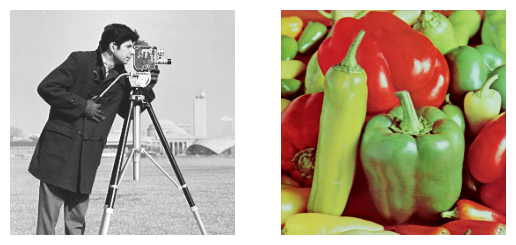

In [13]:
im1 = cv2.imread('Images/cameraman.bmp')
assert im1 is not None, "Buffoon! Thy path is fallacious!"

im2 = cv2.imread('Images/pepper.bmp')
assert im2 is not None, "Buffoon! Thy path is fallacious!"

fig, axes = plt.subplots(1, 2)
axes[0].imshow(im1, cmap="grey")
axes[0].axis("off")
axes[1].imshow(cv2.cvtColor(im2, cv2.COLOR_BGR2RGB))
axes[1].axis("off")
plt.show()

2. Utiliser la méthode `cv2.calcHist()` pour effectuer les calculs d'histogrammes des deux images  (`hist1` pour `im1` et `hist2_B`, `hist2_G` et `hist2_R`  pour `im2`).

In [15]:
hist1 = cv2.calcHist(im1, 1)

error: OpenCV(5.1.0) :-1: error: (-5:Bad argument) in function 'calcHist'
> Overload resolution failed:
>  - calcHist() missing required argument 'mask' (pos 3)
>  - calcHist() missing required argument 'mask' (pos 3)


3. Utiliser le package `matplotlib` pour afficher tous les histogrammes

4. Développer votre propre algorithme pour calculer les histogrammes des deux images (`histp1`  pour `im1` et `histp2_B`, `hispt2_G` et `histp2_R` pour `im2`), puis vérifier que les valeurs de ces  histogrammes correspondent à celles obtenues dans la question 2

In [19]:
histp1 = np.zeros((256), dtype=np.int32)
histp1

array([0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0,
       0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0, 0], dtype=int32)